# Recipe recommender: from the raw recipes to the trained re-ranker
The system takes the ingredients a user has on hand, quickly narrows down the database to recipes sharing the most distinctive ingredients, and then uses a trained ranking model to sort those matches so the easiest-to-make recipes appear at the top

## 1. Setup

In [ ]:
# Import the libraries
import difflib
import json
import re
from collections import Counter
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from scipy.sparse import csr_matrix
from sklearn.model_selection import GroupShuffleSplit

HERE = Path.cwd()
RAW_FILE = HERE / "combined_recipes.csv"
SEED = 42
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})
print("Working folder:", HERE)

Working folder: c:\Users\User\Documents\3RD YEAR\3.2\Artificial Intelligence\SemProject_MLEngine_2\Recipe_reranker_final


## 2. Load and clean the recipes

In [2]:
# Load the raw recipe file that sits next to this notebook.
raw = pd.read_csv(RAW_FILE, encoding="utf-8-sig")
print(raw.shape)
print(raw.columns.tolist())

(8150, 29)
['title', 'index', 'page', 'description', 'ingredients', 'instructions', 'nutrition per 100g of recipe', 'energy(kcal)', 'fat(g)', 'carbohydrates(g)', 'proteins(g)', 'fibre(g)', 'vitamin A(mcg)', 'iron(mg)', 'zinc(mg)', 'F_factor_est', 'source', 'url', 'record_health', 'vote_count', 'rating', 'cuisine', 'course', 'diet', 'prep_time', 'cook_time', 'author', 'tags', 'category']


In [3]:
# Split each raw ingredient text into clean ingredient names, dropping quantities and one-word qualifiers.
QUALIFIERS = {"refined", "iodized", "iodised", "fresh", "dried", "dry", "clear", "whole", "ground", "raw", "boiled", "cooked", "chopped",
              "sliced", "grated", "minced", "crushed", "roasted", "powdered", "peeled", "optional", "ripe", "unripe", "large", "small",
              "medium", "thin", "thick", "finely chopped", "coarsely ground", "soaked", "washed", "cut", "diced"}
UNITS = r"(?:g|kg|mg|ml|l|cups?|tsp|tbsp|teaspoons?|tablespoons?|nos?|pieces?|pcs)"
FILLER = re.compile(r"\b(?:to taste|as required|as needed|as per taste|for garnish|for serving|for frying)\b")

def clean_name(text):
    s = str(text).lower().replace("\u2019", "'").replace("\u00a0", " ")
    s = re.sub(r"^\s*\d+(?:[./]\d+)?\s*(?:" + UNITS + r")?\s+", "", s)
    s = FILLER.sub("", s)
    return re.sub(r"\s+", " ", s).strip(" ,;:.-*\u2022\t")
def parse_ingredients(text):
    if pd.isna(text):
        return []
    names = []
    for line in re.split(r"[\r\n]+", str(text)):
        kept = []
        for part in line.split(","):
            name = clean_name(part)
            if name and not (kept and name in QUALIFIERS):
                kept.append(name)
        names.extend(kept)
    return list(dict.fromkeys(names))
raw["ing"] = raw["ingredients"].apply(parse_ingredients)
for i in range(3):
    print(raw["ing"].iloc[i])
print(raw["ing"].apply(len).describe().round(1).to_dict())

['wheat flour', 'water', 'vanilla essence', 'cardamoms powder', 'yeast', 'cooking oil', 'sugar']
['wheat flour', 'coconut milk', 'white sugar', 'dry yeast', 'cardamom', 'water', 'cooking oil']
['self-raising wheat flour', 'eggs', 'margarine', 'rind from lemons sugar', 'salt', 'cooking fat', 'cow milk', 'water']
{'count': 8150.0, 'mean': 1.1, 'std': 0.8, 'min': 0.0, '25%': 1.0, '50%': 1.0, '75%': 1.0, 'max': 20.0}


In [4]:
# Drop recipes with no ingredients, Hindi-script ingredient names, or a repeated title and ingredient list.
DEVA = re.compile(r"[\u0900-\u097F]")
df = raw.copy()
df["title"] = df["title"].astype(str).str.replace(r"\s+", " ", regex=True).str.strip()
steps = [("raw recipes", len(df))]
df = df[df["ing"].apply(len) > 0]
steps.append(("with at least one ingredient", len(df)))
df = df[~df["ing"].apply(lambda names: any(DEVA.search(n) for n in names))]
steps.append(("without Hindi-script ingredient names", len(df)))
df = df.drop_duplicates(subset=["title", "ingredients"]).reset_index(drop=True)
steps.append(("without exact duplicates", len(df)))
for label, n in steps:
    print(f"{n:6d}  {label}")

  8150  raw recipes
  8138  with at least one ingredient
  6878  without Hindi-script ingredient names
  6878  without exact duplicates


## 3. Ingredient list: merges and parent links

In [5]:
# Hold the approved ingredient decisions: names merged into one entry, and specific kinds linked to a general ingredient.
MERGES = {
    "salt to taste": "salt",
    "green chilli": "green chillies",
    "coriander leaves": "coriander (dhania) leaves",
    "cumin (jeera) seeds": "cumin seeds (jeera)",
    "mustard seeds (rai/ kadugu)": "mustard seeds",
    "dry red chilli": "dry red chillies",
    "coriander (dhania) powder": "coriander powder (dhania)",
    "coriander powde": "coriander powder (dhania)",
    "coconut": "fresh coconut",
    "carrots (gajjar)": "carrot (gajjar)",
    "whole black pepper corns": "whole black peppercorns",
    "cinnamon stick": "cinnamon stick (dalchini)",
    "whole egg": "whole eggs",
    "cloves": "cloves (laung)",
    "carrots": "carrot (gajjar)",
    "carrot": "carrot (gajjar)",
    "green bell peppers": "green bell pepper (capsicum)",
    "cardamom powder": "cardamom powder (elaichi)",
    "gram flour": "gram flour (besan)",
    "bay leaf": "bay leaf (tej patta)",
    "coriander seeds": "coriander (dhania) seeds",
    "whole almonds (badam)": "badam (almond)",
    "slivered almonds (badam)": "badam (almond)",
    "almond": "badam (almond)",
    "potato": "potato (aloo)",
    "lemons": "lemon",
    "raw rice": "rice",
    "green beans": "green beans (french beans)",
    "french beans": "green beans (french beans)",
    "egg": "whole eggs",
    "spinach leaves": "spinach leaves (palak)",
    "spring onion": "spring onion (bulb & greens)",
    "small brinjal (baingan / eggplant)": "brinjal (baingan / eggplant)",
    "cucumbers": "cucumber",
    "bananas": "ripe bananas",
    "cabbage": "cabbage (patta gobi/ muttaikose)",
    "brinjals": "brinjal (baingan / eggplant)",
    "fenugreek leaves": "methi leaves (fenugreek leaves)",
    "beetroots": "beetroot",
    "black cardamom": "black cardamom (badi elaichi)",
    "apples": "apple",
    "sweet potato": "sweet potatoes",
    "shallot": "shallots",
    "black pepper corns": "whole black peppercorns",
    "fresh red chilli": "fresh red chillies",
    "red yellow or green bell pepper (capsicum)": "red yellow and green bell peppers (capsicum)",
    "avocados": "avocado",
    "lemon grass": "lemongrass",
    "oranges": "orange",
    "kokums": "kokum (malabar tamarind)",
    "egg white": "egg whites",
    "dried rose petals": "rose petals",
    "soya chunks": "soy chunks (nuggets)",
    "kashmiri dry red chilli": "kashmiri dry red chillies",
    "lotus seeds": "phool makhana (lotus seeds)",
    "english cucumbers": "english cucumber",
    "canned black beans": "black beans",
    "fresh rose petals": "rose petals",
    "wheat flou": "wheat flour",
    "blackbeans": "black beans",
    "kalpasi flower (stone flower)": "stone flower",
    "papads": "papad",
    "white-rice": "white rice",
    "canned beans": "beans",
    "chicken thigh": "chicken thighs",
    "summac": "sumac",
    "puris used for pani puri": "pani puris",
    "maize flou": "maize flour",
    "margarine (reduced calorie)": "margarine",
    "turkey berries": "sundakkai (turkey berries)",
    "beetel leaves": "betel leaves (paan)",
    "kalamata olives": "kalmatta olives",
    "white wine": "dry white wine",
    "mustar": "mustard",
    "bamboo shots": "bamboo shoots",
    "pigeon pea": "pigeon peas",
    "green gram": "green grams",
    "yoghurt": "yogurt",
    "cow pea leaves": "cow-pea leaves",
    "clamps": "clams",
    "black peppe": "black pepper",
    "potato (aloo)": "potatoes (aloo)",
    "bay leaves (tej patta)": "bay leaf (tej patta)",
    "gingelly oil": "sesame (gingelly) oil",
    "sea salt": "salt",
    "kosher salt": "salt",
    "salt, iodized": "salt",
    "lukewarm water": "water",
    "chilled water": "water",
    "hot water": "water",
    "granulated sugar": "sugar",
    "white sugar": "sugar",
    "blanched tomatoes": "tomatoes",
    "cooking oil": "oil",
    "all-purpose wheat flour": "all purpose flour (maida)",
    "salt and pepper": "salt|black pepper powder",
    "maize and beans": "maize|beans"
}

PARENTS = [
    ("aar maach (fish)", "fish"),
    ("rice noodles (flat)", "rice noodles"),
    ("sunflower oil", "oil"),
    ("red onion", "onion"),
    ("white onion", "onion"),
    ("kashmiri red chilli powder", "red chilli powder"),
    ("green chillies", "chillies"),
    ("caster sugar", "sugar"),
    ("extra virgin olive oil", "oil"),
    ("brown sugar (demerara sugar)", "sugar"),
    ("cane sugar", "sugar"),
    ("yellow mustard seeds", "mustard seeds"),
    ("red mustard seeds", "mustard seeds"),
    ("cherry tomatoes", "tomatoes"),
    ("kashmiri dry red chillies", "dry red chillies"),
    ("canola oil", "oil"),
    ("peanut oil", "oil"),
    ("groundnut oil", "oil")
]
print(len(MERGES), "merges and", len(PARENTS), "parent links")

97 merges and 18 parent links


In [ ]:
# Apply the approved merges, then fold plural and singular spellings of the same name into the more common form.
def resolve(name, path=()):
    if name in path:
        raise ValueError("merge loop: " + " -> ".join(path + (name,)))
    if name not in MERGES:
        return [name]
    result = []
    for target in MERGES[name].split("|"):
        result += resolve(target.strip(), path + (name,))
    return result
def remap_lists(lists, fn):
    out = []
    for names in lists:
        mapped = []
        for n in names:
            mapped.extend(fn(n))
        out.append(list(dict.fromkeys(mapped)))
    return out


def plural_forms(name):
    head, sep, tail = name.partition(" (")
    forms = {head + "s", head + "es"}
    if head.endswith("y"):
        forms.add(head[:-1] + "ies")
    return {form + sep + tail for form in forms}


before = Counter(n for names in df["ing"] for n in set(names))
report = pd.DataFrame({"from": list(MERGES), "to": list(MERGES.values())})
report["recipes_affected"] = report["from"].map(lambda n: before.get(n, 0))
report["status"] = np.where(report["recipes_affected"] > 0, "applied", "name not in data")
df["ing"] = remap_lists(df["ing"], resolve)

counts = Counter(n for names in df["ing"] for n in set(names))
fold = {}
for name in counts:
    for form in plural_forms(name):
        if form in counts:
            if counts[name] >= counts[form]:
                fold[form] = name
            else:
                fold[name] = form


def fold_name(name):
    seen = set()
    while name in fold and name not in seen:
        seen.add(name)
        name = fold[name]
    return [name]


df["ing"] = remap_lists(df["ing"], fold_name)
print(report["status"].value_counts().to_dict())
print(len(fold), "plural or singular spellings folded together")

{'name not in data': 64, 'applied': 33}
4 plural or singular spellings folded together


In [7]:
# Build the ingredient list, the recipe-by-ingredient matrix, the ingredient weights and the parent-aware matrix.
vocab = sorted({n for names in df["ing"] for n in names})
idx = {n: i for i, n in enumerate(vocab)}
N, V = len(df), len(vocab)
Xd = np.zeros((N, V), np.float32)
for r, names in enumerate(df["ing"]):
    Xd[r, [idx[n] for n in names]] = 1
freq = Xd.sum(0)
w = np.log(1 + N / freq).astype(np.float32)
len_r = Xd.sum(1)
Xw = Xd * w
Xw_sum = Xw.sum(1, keepdims=True)
main_idx = Xw.argmax(1)
PARENT_LINKS = sorted({(resolve(c)[0], resolve(p)[0]) for c, p in PARENTS})
PARENT_LINKS = [(c, p) for c, p in PARENT_LINKS if c in idx and p in idx and c != p]
Pm = np.zeros((V, V), np.float32)
for c, p in PARENT_LINKS:
    Pm[idx[c], idx[p]] = 1
Xc = ((Xd @ Pm) > 0).astype(np.float32)
M = Xd + 0.5 * Xc * (1 - Xd)
print(N, "recipes,", V, "ingredients,", len(PARENT_LINKS), "of", len(PARENTS), "parent links present")

6878 recipes, 6899 ingredients, 0 of 18 parent links present


## 4. Exploratory data analysis

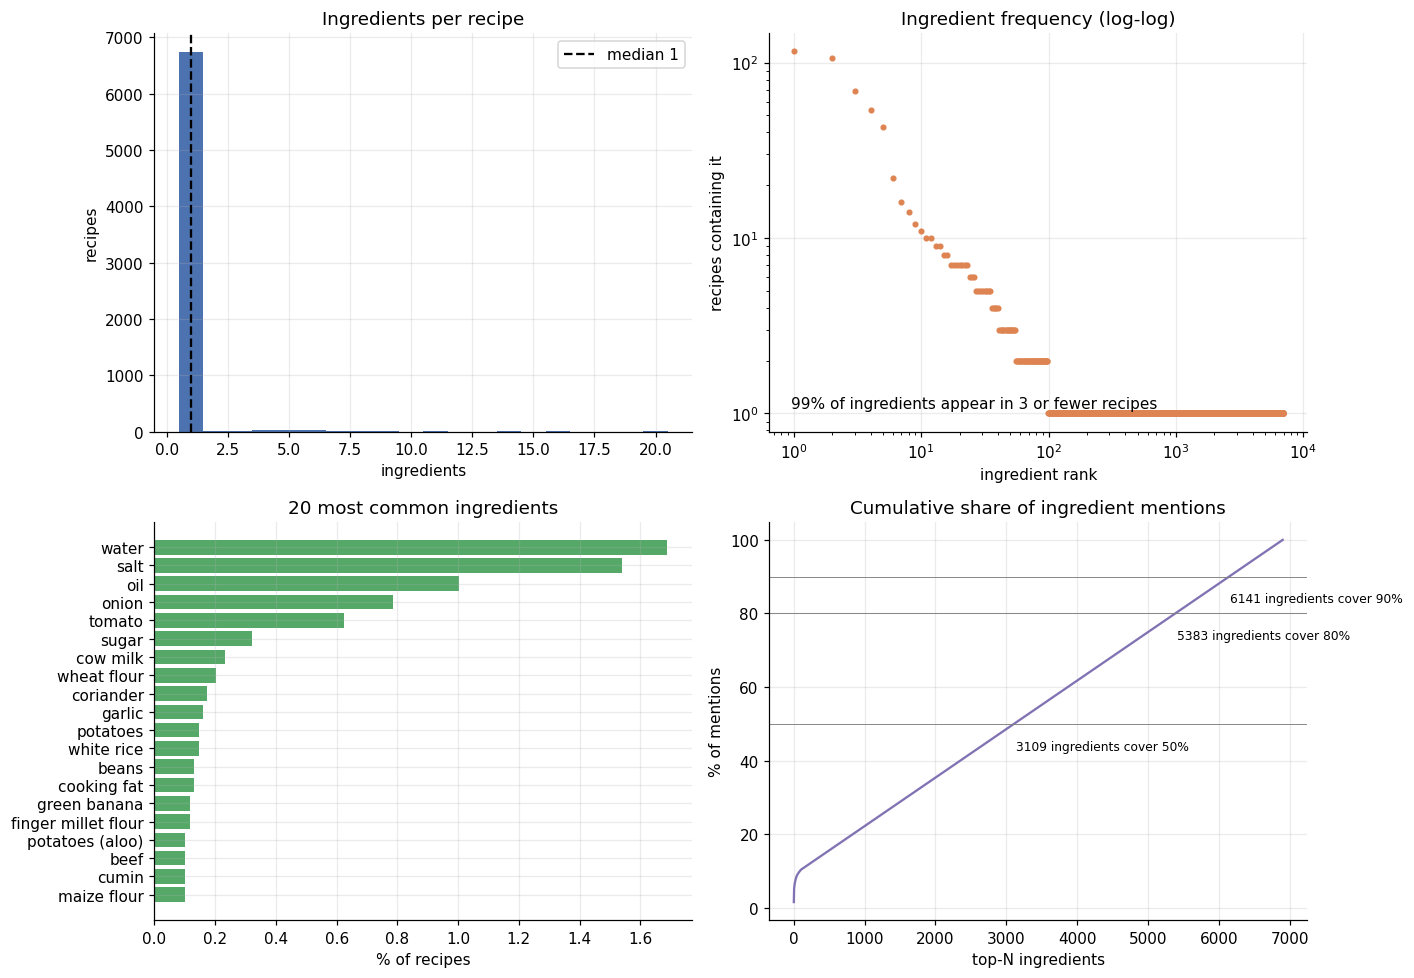

In [8]:
# Plot the recipe lengths, the long tail of ingredient frequencies, the most common ingredients and the cumulative coverage.
order = np.argsort(-freq)
cum = np.cumsum(freq[order]) / freq.sum() * 100
short = lambda s, n=28: s if len(s) <= n else s[: n - 1] + "\u2026"
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
ax[0, 0].hist(len_r, bins=np.arange(0.5, len_r.max() + 1.5), color="#4C72B0")
ax[0, 0].axvline(np.median(len_r), color="k", ls="--", label=f"median {np.median(len_r):.0f}")
ax[0, 0].set(title="Ingredients per recipe", xlabel="ingredients", ylabel="recipes")
ax[0, 0].legend()
ax[0, 1].loglog(np.arange(1, V + 1), np.maximum(freq[order], 1), ".", color="#DD8452")
ax[0, 1].set(title="Ingredient frequency (log-log)", xlabel="ingredient rank", ylabel="recipes containing it")
ax[0, 1].text(0.04, 0.06, f"{(freq <= 3).mean():.0%} of ingredients appear in 3 or fewer recipes", transform=ax[0, 1].transAxes)
top20 = order[:20][::-1]
ax[1, 0].barh([short(vocab[i]) for i in top20], freq[top20] / N * 100, color="#55A868")
ax[1, 0].set(title="20 most common ingredients", xlabel="% of recipes")
ax[1, 1].plot(np.arange(1, V + 1), cum, color="#8172B3")
for p in (50, 80, 90):
    n_p = int(np.searchsorted(cum, p) + 1)
    ax[1, 1].axhline(p, color="grey", lw=0.6)
    ax[1, 1].annotate(f"{n_p} ingredients cover {p}%", (n_p, p), xytext=(n_p + 20, p - 7), fontsize=8)
ax[1, 1].set(title="Cumulative share of ingredient mentions", xlabel="top-N ingredients", ylabel="% of mentions")
fig.tight_layout()
fig.savefig(HERE / "eda_ingredients.png", bbox_inches="tight")
plt.show()

## 5. Train, validation and test split

In [ ]:
# Group near-duplicate recipes and split the groups 80/10/10 into train, validation and test.
sparse_X = csr_matrix(Xd)
parent_uf = list(range(N))
def find(a):
    while parent_uf[a] != a:
        parent_uf[a] = parent_uf[parent_uf[a]]
        a = parent_uf[a]
    return a
for s in range(0, N, 1000):
    inter = (sparse_X[s:s + 1000] @ sparse_X.T).toarray()
    union = len_r[s:s + 1000, None] + len_r[None, :] - inter
    ii, jj = np.where(inter / union >= 0.8)
    for a, b in zip(ii + s, jj):
        if a < b:
            parent_uf[find(a)] = find(b)
df["group"] = [find(i) for i in range(N)]
train_idx, rest_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(df, groups=df["group"]))
rest = df.iloc[rest_idx]
val_rel, test_rel = next(GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=SEED).split(rest, groups=rest["group"]))
df["split"] = "train"
df.loc[rest.index[val_rel], "split"] = "val"
df.loc[rest.index[test_rel], "split"] = "test"
assert (df.groupby("group")["split"].nunique() == 1).all()
grp = df["group"].values
train_rows, val_rows, test_rows = (np.flatnonzero(df["split"].values == s) for s in ("train", "val", "test"))
group_size = np.bincount(grp, minlength=grp.max() + 1)
print(len(train_rows), len(val_rows), len(test_rows), "recipes in train, validation and test")
print(round(float((group_size[grp] > 1).mean()), 3), "share of recipes that have a near-duplicate")

5501 688 689 recipes in train, validation and test
0.006 share of recipes that have a near-duplicate


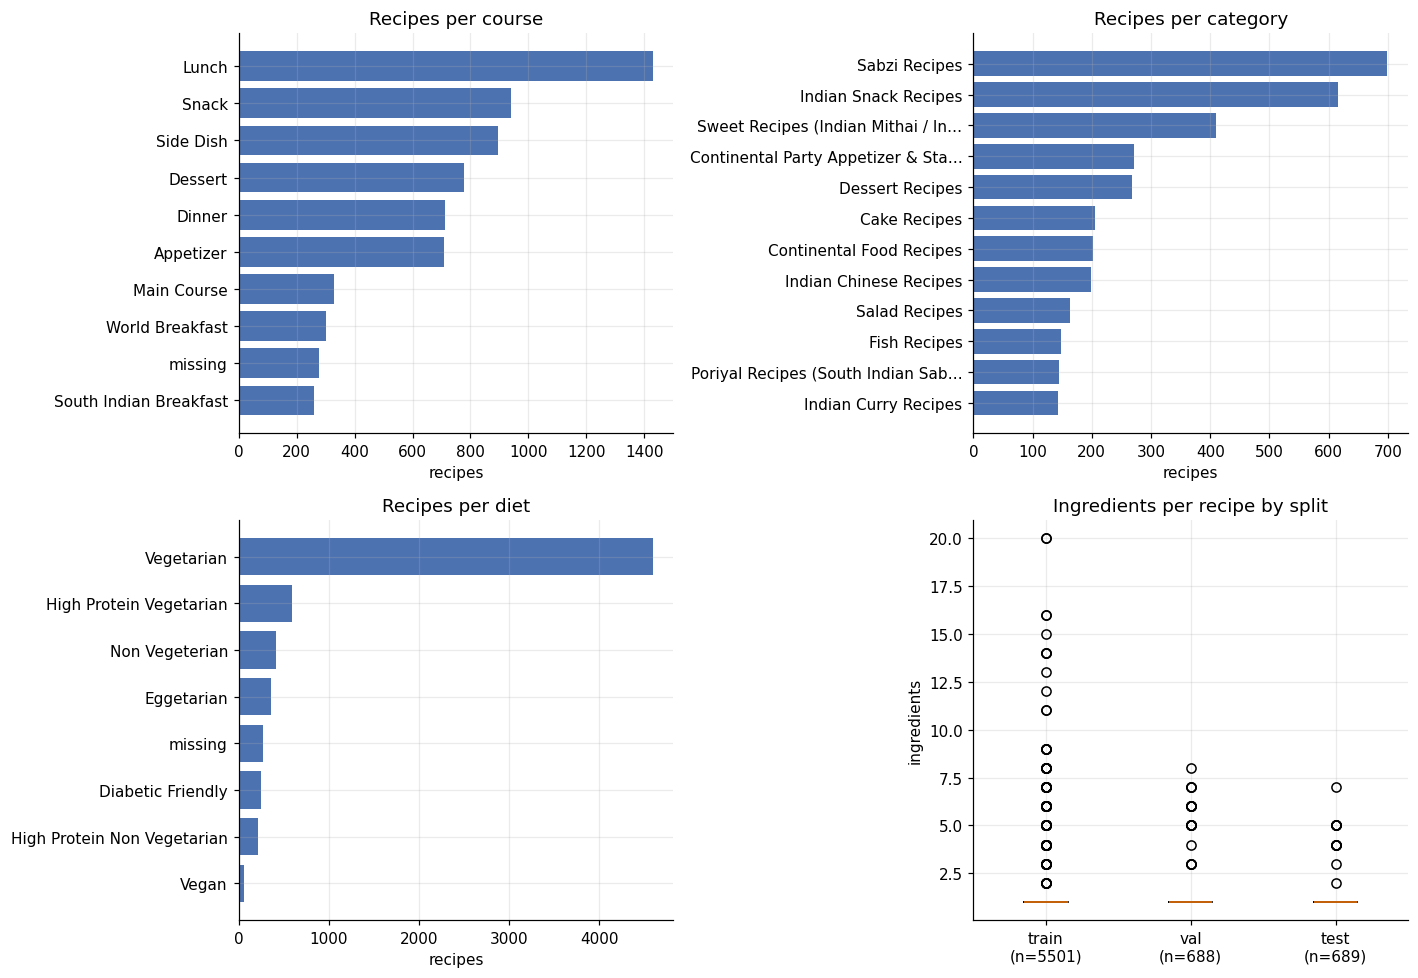

In [10]:
# Plot recipes per course, category and diet, and compare recipe lengths across the three splits.
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
for a, col, top_n in ((ax[0, 0], "course", 10), (ax[0, 1], "category", 12), (ax[1, 0], "diet", 8)):
    if col in df.columns:
        vc = df[col].fillna("missing").value_counts().head(top_n)[::-1]
        a.barh([short(str(i), 34) for i in vc.index], vc.values, color="#4C72B0")
        a.set(title=f"Recipes per {col}", xlabel="recipes")
    else:
        a.set_visible(False)
split_lengths = [len_r[df["split"].values == s] for s in ("train", "val", "test")]
ax[1, 1].boxplot(split_lengths)
ax[1, 1].set_xticklabels([f"{s}\n(n={len(p)})" for s, p in zip(("train", "val", "test"), split_lengths)])
ax[1, 1].set(title="Ingredients per recipe by split", ylabel="ingredients")
fig.tight_layout()
fig.savefig(HERE / "eda_metadata_and_splits.png", bbox_inches="tight")
plt.show()

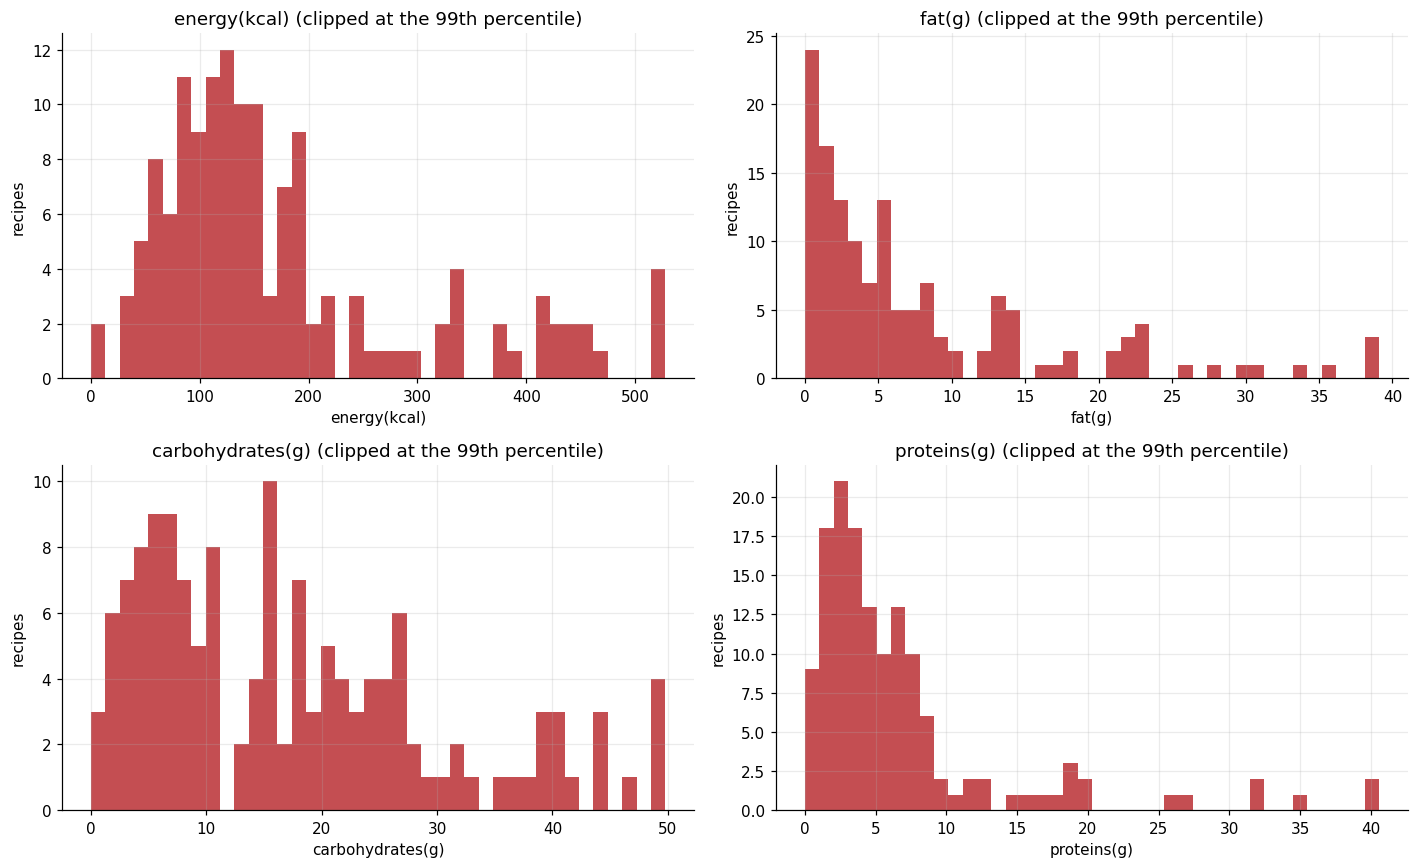

6878 recipes, 6899 ingredients; ingredients per recipe: median 1, IQR 1-1
99% of ingredients appear in 3 or fewer recipes; the top 5383 ingredients cover 80% of all mentions
most common: water (2%), salt (2%), oil (1%), onion (1%), tomato (1%)
course: 13 values; largest is Lunch (21%)
category: 99 values; largest is Sabzi Recipes (10%)
diet: 10 values; largest is Vegetarian (67%)
mean ingredients per recipe by split: {'train': 1.1, 'val': 1.13, 'test': 1.06}


In [11]:
# Plot the nutrition columns that are present and print the facts to quote in the report.
nut = [c for c in ("energy(kcal)", "fat(g)", "carbohydrates(g)", "proteins(g)") if c in df.columns]
if nut:
    fig, ax = plt.subplots(2, 2, figsize=(13, 8))
    for a, c in zip(ax.ravel(), nut):
        v = pd.to_numeric(df[c], errors="coerce").dropna()
        a.hist(v.clip(upper=v.quantile(0.99)), bins=40, color="#C44E52")
        a.set(title=c + " (clipped at the 99th percentile)", xlabel=c, ylabel="recipes")
    for a in ax.ravel()[len(nut):]:
        a.set_visible(False)
    fig.tight_layout()
    fig.savefig(HERE / "eda_nutrition.png", bbox_inches="tight")
    plt.show()
print(f"{N} recipes, {V} ingredients; ingredients per recipe: median {np.median(len_r):.0f}, IQR {np.percentile(len_r, 25):.0f}-{np.percentile(len_r, 75):.0f}")
print(f"{(freq <= 3).mean():.0%} of ingredients appear in 3 or fewer recipes; the top {int(np.searchsorted(cum, 80) + 1)} ingredients cover 80% of all mentions")
print("most common:", ", ".join(f"{vocab[i]} ({freq[i] / N:.0%})" for i in order[:5]))
for col in ("course", "category", "diet"):
    if col in df.columns:
        share = df[col].fillna("missing").value_counts(normalize=True)
        print(f"{col}: {df[col].nunique()} values; largest is {share.index[0]} ({share.iloc[0]:.0%})")
print("mean ingredients per recipe by split:", {s: round(float(p.mean()), 2) for s, p in zip(("train", "val", "test"), split_lengths)})

## 6. Simulated shopper queries

In [ ]:
# Define the simulated shopper queries: normal picks, tiny picks, noisy picks, and picks that miss the main ingredient.
POP = (freq / freq.sum()).astype(np.float64)
MODES = ("normal", "tiny", "noisy", "no_main")


def one_query(r, mode, rng):
    pool = np.flatnonzero(Xd[r])
    if len(pool) <= 2:
        return Xd[r].copy()
    k = min(len(pool), max(2, int(round(len(pool) * rng.uniform(0.5, 1.0)))))
    
    if mode == "uniform":
        prob = None
    elif mode == "tiny":
        prob = None
        k = 2
    else:
        # Cast to float64 to prevent precision drift in probabilities
        w_pool = w[pool].astype(np.float64)
        wt = w_pool if mode == "rare" else (w.max() - w_pool + 0.01)
        total = wt.sum()
        prob = (wt / total) if total > 0 else None
    chosen = rng.choice(pool, size=k, replace=False, p=prob)
    q = np.zeros(V, np.float32)
    q[chosen] = 1
    return q
def make_set(rows, mode, per, seed):
    rng = np.random.default_rng(seed)
    eligible = [r for r in rows if len_r[r] >= 4]
    src = np.repeat(eligible, per)
    return np.stack([one_query(r, mode, rng) for r in src]), src

def make_mixed(rows, n, seed, probs=(0.4, 0.25, 0.2, 0.15)):
    rng = np.random.default_rng(seed)
    eligible = np.array([r for r in rows if len_r[r] >= 4])
    src = rng.choice(eligible, size=n)
    picked = rng.choice(len(MODES), size=n, p=probs)
    return np.stack([one_query(r, MODES[m], rng) for r, m in zip(src, picked)]), src
def make_labelled(rows, base_seed):
    parts = [make_set(rows, m, 2, base_seed + i) for i, m in enumerate(MODES)]
    U = np.concatenate([p[0] for p in parts])
    src = np.concatenate([p[1] for p in parts])
    modes = np.concatenate([[m] * len(p[1]) for m, p in zip(MODES, parts)])
    return U, src, modes
print(MODES)

modes: ('normal', 'tiny', 'noisy', 'no_main')


## 7. Overlap score, candidates and features

In [ ]:
# Define the overlap score, the shortlist of 200 candidates per query, and the seven features the re-ranker sees.
K = min(200, N - 1)
FEATURES = ["user_recall", "user_recall_parent", "coverage", "log_length", "log_missing", "log_unused_query", "main_ingredient_chosen"]


def candidate_features(U, alpha, batch=500):
    cands, feats, valid = [], [], []
    for s in range(0, len(U), batch):
        Ub = U[s:s + batch]
        uw = Ub * w
        usum = uw.sum(1)
        mw = Xd @ uw.T
        u_exact = mw / usum
        u_par = (M @ uw.T) / usum
        cov = mw / Xw_sum
        matched = Xd @ Ub.T
        base = alpha * u_exact + (1 - alpha) * cov
        cand = np.argpartition(-base, K, axis=0)[:K].T
        take = lambda a: np.take_along_axis(a.T, cand, axis=1)
        length = len_r[cand]
        m_c = take(matched)
        qs = Ub.sum(1, keepdims=True)
        feats.append(np.stack([take(u_exact), take(u_par), take(cov), np.log1p(length), np.log1p(length - m_c),
                               np.log1p(qs - m_c), take(Ub[:, main_idx].T)], axis=2).astype(np.float32))
        cands.append(cand)
        valid.append(m_c > 0)
    return np.concatenate(cands), np.concatenate(feats), np.concatenate(valid)
print(K, "candidates per query,", len(FEATURES), "features")

200 candidates per query, 7 features


In [14]:
# Define precision, recall and F1 for the top k recommendations, counting ties against the model.
def pess_rank(S):
    srt = np.sort(S, axis=1)
    return np.stack([S.shape[1] - np.searchsorted(srt[q], S[q], side="left") for q in range(len(S))])
def prf(S, G, total, ks=(1,)):
    r = pess_rank(S)
    out = {}
    for k in ks:
        pred = r <= k
        tp = int((pred & G).sum())
        p = tp / max(int(pred.sum()), 1)
        rc = tp / int(total.sum())
        out[k] = (p, rc, 2 * p * rc / max(p + rc, 1e-12))
    return out


## 8. Training and validation

In [ ]:
# Choose the overlap weight alpha on the validation queries by comparing the F1 of the single best recommendation.
Uv, sv, mv = make_labelled(val_rows, SEED + 10)
def sweep_alpha(U, src, alphas, batch=250):
    tp = dict.fromkeys(alphas, 0)
    npred = dict.fromkeys(alphas, 0)
    total = int(group_size[grp[src]].sum())
    for s in range(0, len(U), batch):
        Ub, sb = U[s:s + batch], src[s:s + batch]
        uw = Ub * w
        mw = Xd @ uw.T
        u_exact = mw / uw.sum(1)
        cov = mw / Xw_sum
        G = grp[None, :] == grp[sb][:, None]
        for a in alphas:
            pred = pess_rank((a * u_exact + (1 - a) * cov).T) <= 1
            tp[a] += int((pred & G).sum())
            npred[a] += int(pred.sum())
    rows = []
    for a in alphas:
        p = tp[a] / max(npred[a], 1)
        rc = tp[a] / total
        rows.append((a, p, rc, 2 * p * rc / max(p + rc, 1e-12)))
    return pd.DataFrame(rows, columns=["alpha", "precision", "recall", "f1"])




alpha_table = sweep_alpha(Uv, sv, (0.4, 0.5, 0.6, 0.7, 0.8))
ALPHA = float(alpha_table.loc[alpha_table["f1"].idxmax(), "alpha"])
print(alpha_table.round(4).to_string(index=False))
print("chosen alpha:", ALPHA)

 alpha  precision  recall     f1
   0.4     0.5159  0.4276 0.4676
   0.5     0.5238  0.4342 0.4748
   0.6     0.5317  0.4408 0.4820
   0.7     0.5317  0.4408 0.4820
   0.8     0.5317  0.4408 0.4820
chosen alpha: 0.6


In [ ]:
# Train the linear re-ranker on simulated queries from training recipes and pick its regularisation on validation.
def fit_linear(Z, G, lam):
    keep = G.any(1)
    Zt = Z[keep].astype(np.float64)
    T = G[keep].astype(np.float64)
    T = T / T.sum(1, keepdims=True)
    n = len(Zt)
    def objective(wv):
        s = Zt @ wv
        s = s - s.max(1, keepdims=True)
        log_p = s - np.log(np.exp(s).sum(1, keepdims=True))
        p = np.exp(log_p)
        loss = -(T * log_p).sum() / n + lam * wv @ wv
        grad = np.einsum("qkf,qk->f", Zt, p - T) / n + 2 * lam * wv
        return loss, grad

    return minimize(objective, np.zeros(Z.shape[2]), jac=True, method="L-BFGS-B").x

def rerank_scores(Z, valid, weights):
    return np.where(valid, Z @ weights, -1e9)
U_train, s_train = make_mixed(train_rows, 8000, SEED + 1)
C_train, F_train, V_train = candidate_features(U_train, ALPHA)
G_train = grp[C_train] == grp[s_train][:, None]
flat = F_train.reshape(-1, len(FEATURES))
mu, sd = flat.mean(0), flat.std(0) + 1e-6
Z_train = (F_train - mu) / sd

C_val, F_val, V_val = candidate_features(Uv, ALPHA)
G_val = grp[C_val] == grp[sv][:, None]
total_val = group_size[grp[sv]]
Z_val = (F_val - mu) / sd
fits = {}
for lam in (1e-4, 1e-3, 1e-2, 1e-1):
    fits[lam] = fit_linear(Z_train, G_train, lam)
lam_table = pd.DataFrame(
    [(lam, *prf(rerank_scores(Z_val, V_val, fits[lam]), G_val, total_val)[1]) for lam in fits],
    columns=["lambda", "precision", "recall", "f1"]
)
LAM = float(lam_table.loc[lam_table["f1"].idxmax(), "lambda"])
WEIGHTS = fits[LAM]
print(lam_table.round(4).to_string(index=False))
print("chosen lambda:", LAM)
print(dict(zip(FEATURES, WEIGHTS.round(3))))

 lambda  precision  recall     f1
 0.0001     0.7414  0.5658 0.6418
 0.0010     0.7414  0.5658 0.6418
 0.0100     0.5635  0.4671 0.5108
 0.1000     0.5317  0.4408 0.4820
chosen lambda: 0.0001
{'user_recall': np.float64(2.298), 'user_recall_parent': np.float64(2.298), 'coverage': np.float64(-1.676), 'log_length': np.float64(0.633), 'log_missing': np.float64(-3.208), 'log_unused_query': np.float64(-1.36), 'main_ingredient_chosen': np.float64(-0.007)}


## 9. Evaluation: precision, recall and F1

In [17]:
# Score the validation and test queries with the overlap baseline and the re-ranker and compute precision, recall and F1.
Ut, st, mt = make_labelled(test_rows, SEED + 20)
C_test, F_test, V_test = candidate_features(Ut, ALPHA)
G_test = grp[C_test] == grp[st][:, None]
total_test = group_size[grp[st]]
Z_test = (F_test - mu) / sd
data = {
    "Validation": dict(F=F_val, Z=Z_val, valid=V_val, G=G_val, total=total_val, modes=mv),
    "Test": dict(F=F_test, Z=Z_test, valid=V_test, G=G_test, total=total_test, modes=mt),
}
KS = tuple(range(1, 11))
rows = []
for split, d in data.items():
    base_scores = np.where(d["valid"], ALPHA * d["F"][:, :, 0] + (1 - ALPHA) * d["F"][:, :, 2], -1e9)
    model_scores = rerank_scores(d["Z"], d["valid"], WEIGHTS)
    for name, S in (("Overlap baseline", base_scores), ("Re-ranker", model_scores)):
        for k, (p, rc, f1) in prf(S, d["G"], d["total"], KS).items():
            rows.append((name, split, "all", k, p, rc, f1))
        for m in MODES:
            sel = d["modes"] == m
            p, rc, f1 = prf(S[sel], d["G"][sel], d["total"][sel])[1]
            rows.append((name, split, m, 1, p, rc, f1))
metrics_table = pd.DataFrame(rows, columns=["model", "split", "queries", "k", "precision", "recall", "f1"])
print("source recipe among the candidates:", {s: round(float(d["G"].any(1).mean()), 3) for s, d in data.items()})
print(metrics_table[(metrics_table["queries"] == "all") & (metrics_table["k"] == 1)].round(4).to_string(index=False))

source recipe among the candidates: {'Validation': 1.0, 'Test': 1.0}
           model      split queries  k  precision  recall     f1
Overlap baseline Validation     all  1     0.5317  0.4408 0.4820
       Re-ranker Validation     all  1     0.7414  0.5658 0.6418
Overlap baseline       Test     all  1     0.8000  0.7727 0.7861
       Re-ranker       Test     all  1     0.8250  0.7500 0.7857


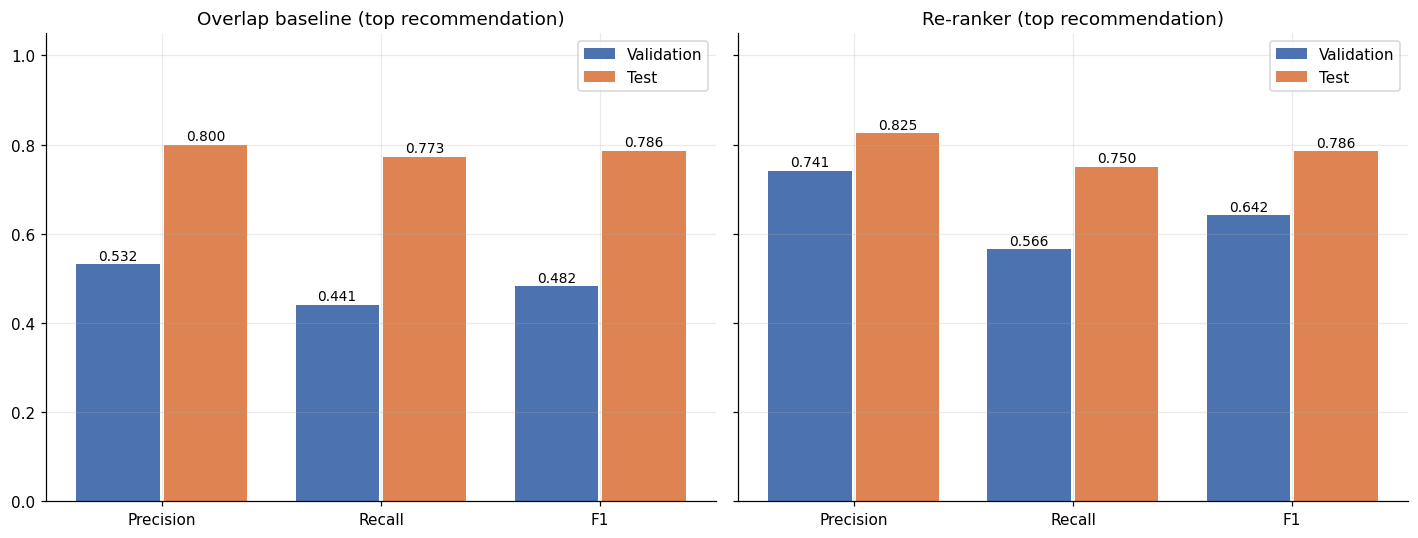

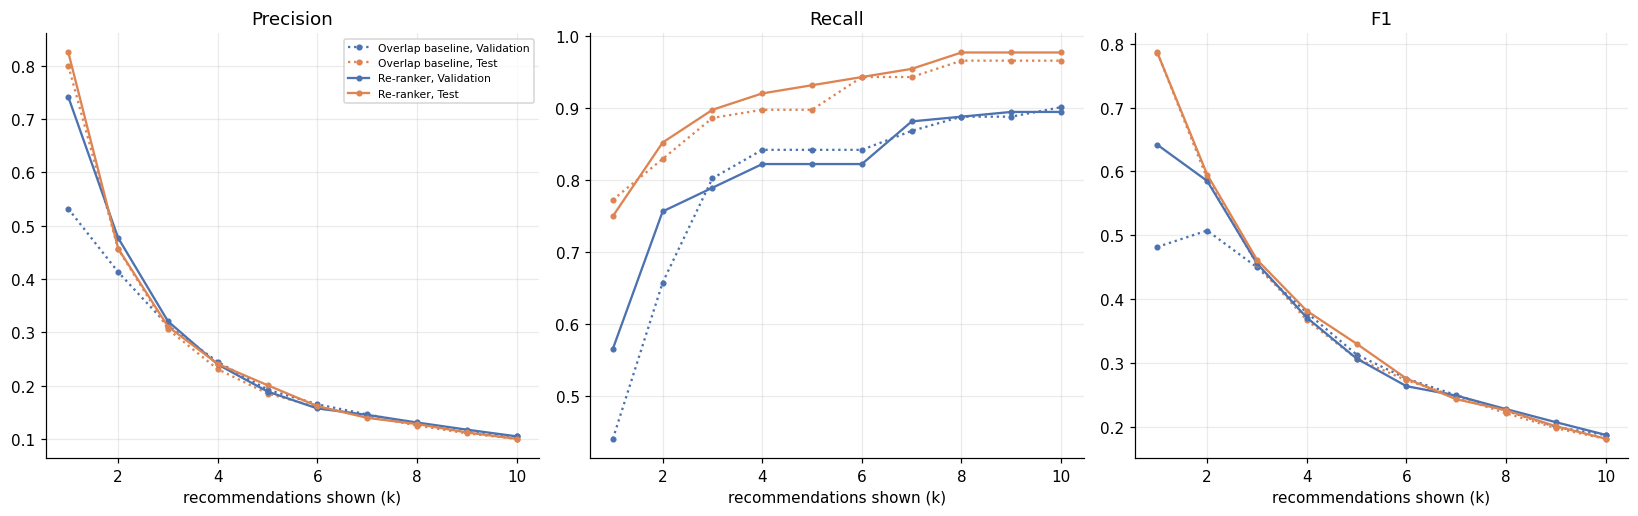

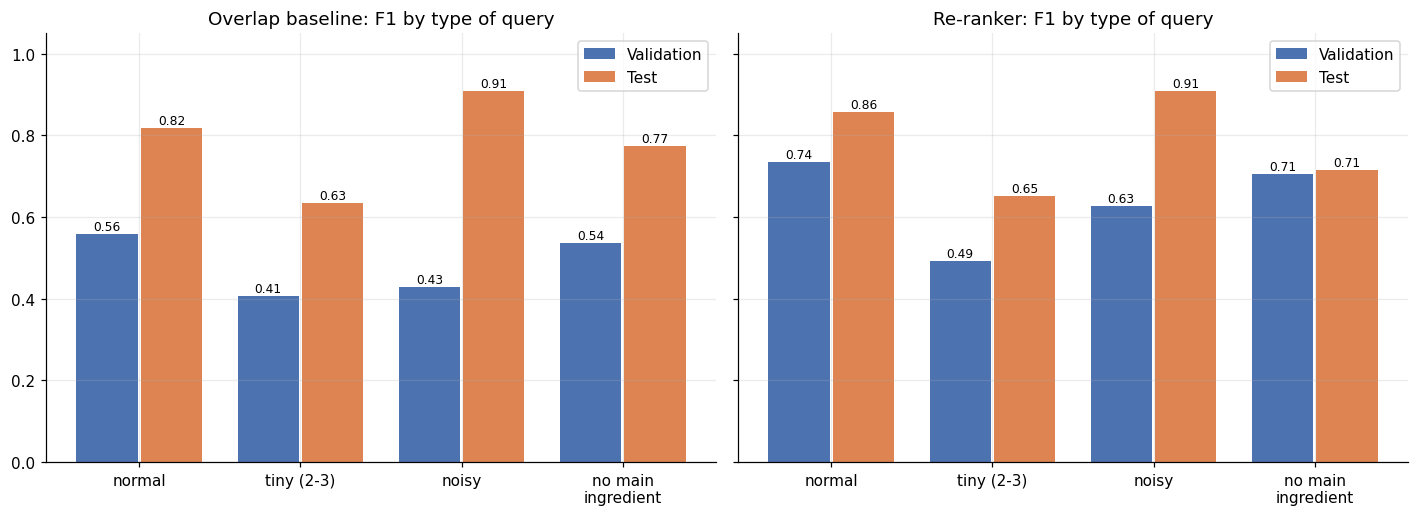

In [ ]:
# Plot precision, recall and F1 for validation against test, at the top recommendation and as more recipes are shown.
MODELS = ("Overlap baseline", "Re-ranker")
COLORS = {"Validation": "#4C72B0", "Test": "#DD8452"}
top1 = metrics_table[(metrics_table["queries"] == "all") & (metrics_table["k"] == 1)]
fig, ax = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for a, model in zip(ax, MODELS):
    for off, split in ((-0.2, "Validation"), (0.2, "Test")):
        row = top1[(top1["model"] == model) & (top1["split"] == split)].iloc[0]
        vals = [row["precision"], row["recall"], row["f1"]]
        bars = a.bar(np.arange(3) + off, vals, 0.38, label=split, color=COLORS[split])
        for b, v in zip(bars, vals):
            a.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.3f}", ha="center", fontsize=9)
    a.set_xticks(range(3))
    a.set_xticklabels(["Precision", "Recall", "F1"])
    a.set_ylim(0, 1.05)
    a.set_title(model + " (top recommendation)")
    a.legend()
fig.tight_layout()
fig.savefig(HERE / "eval_precision_recall_f1.png", bbox_inches="tight")
plt.show()
fig, ax = plt.subplots(1, 3, figsize=(15, 4.8), sharex=True)
curves = metrics_table[metrics_table["queries"] == "all"]
for a, metric in zip(ax, ("precision", "recall", "f1")):
    for model, style in (("Overlap baseline", ":"), ("Re-ranker", "-")):
        for split in ("Validation", "Test"):
            c = curves[(curves["model"] == model) & (curves["split"] == split)].sort_values("k")
            a.plot(c["k"], c[metric], style, color=COLORS[split], marker="o", ms=3, label=f"{model}, {split}")
    a.set(title=metric.upper() if metric == "f1" else metric.capitalize(), xlabel="recommendations shown (k)")
ax[0].legend(fontsize=7)
fig.tight_layout()
fig.savefig(HERE / "eval_precision_recall_f1_by_k.png", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
by_mode = metrics_table[(metrics_table["queries"] != "all") & (metrics_table["k"] == 1)]
for a, model in zip(ax, MODELS):
    for off, split in ((-0.2, "Validation"), (0.2, "Test")):
        vals = [by_mode[(by_mode["model"] == model) & (by_mode["split"] == split) & (by_mode["queries"] == m)]["f1"].iloc[0] for m in MODES]
        bars = a.bar(np.arange(len(MODES)) + off, vals, 0.38, label=split, color=COLORS[split])
        for b, v in zip(bars, vals):
            a.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.2f}", ha="center", fontsize=8)
    a.set_xticks(range(len(MODES)))
    a.set_xticklabels(["normal", "tiny (2-3)", "noisy", "no main\ningredient"])
    a.set_ylim(0, 1.05)
    a.set_title(model + ": F1 by type of query")
    a.legend()
fig.tight_layout()
fig.savefig(HERE / "eval_f1_by_query_type.png", bbox_inches="tight")
plt.show()

## 10. Save the model

In [19]:
# Save the cleaned data, vocabulary, parent links, merge report, metrics and the trained re-ranker next to this notebook.
keep_cols = [c for c in ("title", "category", "course", "diet", "instructions") if c in df.columns]
out_df = df[keep_cols].copy()
out_df["ingredients"] = df["ing"].apply(lambda names: json.dumps(names, ensure_ascii=False))
out_df["group"] = df["group"]
out_df["split"] = df["split"]
out_df.to_csv(HERE / "recipes_clean.csv", index=False, encoding="utf-8-sig")
json.dump(vocab, open(HERE / "ingredient_vocabulary.json", "w", encoding="utf-8"), ensure_ascii=False)
pd.DataFrame(PARENT_LINKS, columns=["child", "parent"]).to_csv(HERE / "ingredient_parents.csv", index=False)
report.to_csv(HERE / "ingredient_merge_report.csv", index=False)
metrics_table.to_csv(HERE / "evaluation_metrics.csv", index=False)
model_file = {"features": FEATURES, "weights": WEIGHTS.tolist(), "mean": mu.tolist(), "std": sd.tolist(),
              "alpha": ALPHA, "candidates": K, "lambda": LAM}
json.dump(model_file, open(HERE / "reranker.json", "w"), indent=2)
print(sorted(p.name for p in HERE.iterdir() if p.is_file()))

['RecipeRecommender_final.ipynb', 'combined_recipes.csv', 'eda_ingredients.png', 'eda_metadata_and_splits.png', 'eda_nutrition.png', 'eval_f1_by_query_type.png', 'eval_precision_recall_f1.png', 'eval_precision_recall_f1_by_k.png', 'evaluation_metrics.csv', 'ingredient_merge_report.csv', 'ingredient_parents.csv', 'ingredient_vocabulary.json', 'recipes_clean.csv', 'reranker.json']


In [21]:
# Recommend recipes for example ingredient lists with the trained re-ranker.
def closest(name):
    t = name.lower().strip()
    if t in idx:
        return t
    hits = sorted((n for n in vocab if t in n), key=lambda n: -freq[idx[n]])
    if hits:
        return hits[0]
    near = difflib.get_close_matches(t, vocab, n=1, cutoff=0.75)
    return near[0] if near else None


def recommend(names, top_n=5):
    chosen = [n for n in dict.fromkeys(closest(x) for x in names) if n]
    if not chosen:
        return
    u = np.zeros((1, V), np.float32)
    u[0, [idx[n] for n in chosen]] = 1
    cand, feat, valid = candidate_features(u, ALPHA)
    score = rerank_scores((feat - mu) / sd, valid, WEIGHTS)[0]
    print("\nChosen:", ", ".join(chosen))
    for j in np.argsort(-score)[:top_n]:
        if score[j] < -1e8:
            break
        r = cand[0, j]
        have = [vocab[i] for i in np.flatnonzero(Xd[r]) if vocab[i] in chosen]
        need = [vocab[i] for i in np.flatnonzero(Xd[r]) if vocab[i] not in chosen]
        print(f"  {df['title'].iloc[r][:58]:58s} uses {len(have)}/{len(chosen)} | needs {len(need)} more")
    print()
for example in (["coconut milk"], ["onion", "tomato", "oil"], ["rice", "sugar", "milk"]):
    recommend(example)


Chosen: coconut milk
  Rice Flour Porridge (Uji wa Mchele)                        uses 1/1 | needs 4 more
  Vimumunya vya Chumvi (Pumpkin & Coconut Milk)              uses 1/1 | needs 3 more
  Vimumunya vya Sukari (Sweetened Pumpkin & Coconut Milk)    uses 1/1 | needs 4 more
  Mseto wa Ndengu (Rice with Green Grams)                    uses 1/1 | needs 5 more
  Mahamri (Swahili Doughnut)                                 uses 1/1 | needs 6 more


Chosen: onion, tomato, oil
  Stewed Goat Meat                                           uses 3/3 | needs 2 more
  Terere (Stir-fried Amaranth Leaves)                        uses 3/3 | needs 2 more
  Sukuma Wiki (Stir-fried Kales)                             uses 3/3 | needs 2 more
  Omelette                                                   uses 3/3 | needs 2 more
  Aluru (Stewed Quails)                                      uses 3/3 | needs 3 more


Chosen: rice, sugar, milk
  Bulrush Millet Porridge (Uji wa Mawele)                    uses 1/3 |